In [1]:
import os
os.chdir('/home/hrayrh/projects/incontext_spurious')
os.environ['DATA_ROOT_DIR'] = '/home/hrayrh/data'

In [2]:
import sys
sys.path.append('/home/hrayrh/projects/incontext_spurious')

In [5]:
from collections import Counter
from matplotlib import pyplot as plt
%matplotlib inline
import numpy as np
from sklearn.linear_model import LogisticRegression
from src.datamodules.datasets import INaturalistEmbContextsDatasetV2

# Inspect INaturalist2017Dataset

In [11]:
train = INaturalistEmbContextsDatasetV2(
    dataset_path='/home/hrayrh/data/inaturalist2017/',
    encoding_extractor='dinov2_vitb14',
    data_length=400000,
    class1_split='inner_train',
    class2_split='inner_train',
    context_class_size=200,
    context_minority_group_proportion=0.0,
    query_minority_group_proportion=0.0,
    spurious_setting='inat_no_spurious',
    sp_token_generation_mode='opposite',
    use_context_as_intermediate_queries=True,
    permute_input_dim=False,
)

  # datamodule.train_len=4000000 \
  # datamodule.batch_size=40 \
  # datamodule.num_workers=8 \
  # datamodule.val_sets="[inner, inner_outer, outer]" \

In [12]:
len(train)

400000

In [79]:
input_seq, context, queries, query_indices = train[1]

In [80]:
input_seq.shape

(1200, 768)

In [81]:
context.shape

(400, 3)

In [82]:
queries.shape

(400, 3)

In [83]:
query_indices.shape

(400,)

In [84]:
query_indices[:10]

array([ 2,  5,  8, 11, 14, 17, 20, 23, 26, 29])

In [85]:
np.linalg.norm(input_seq, axis=1)

array([47.55589 , 48.003357, 48.35494 , ..., 49.818333, 48.003357,
       48.201237], dtype=float32)

In [86]:
train._avg_norm

array(48.12815, dtype=float32)

In [87]:
input_seq[2]

array([ 0.00000000e+00,  0.00000000e+00,  1.00000000e+00,  1.61211625e-01,
       -1.72253549e+00, -3.78053457e-01,  2.68297100e+00, -8.98549259e-01,
        5.81097305e-01,  6.79971993e-01,  1.11349261e+00, -3.15708041e+00,
       -2.27662921e+00, -3.93953919e-01, -1.53198230e+00, -6.75601006e-01,
        1.53281474e+00,  1.01529706e+00,  4.00399625e-01,  2.70676255e+00,
       -1.12068033e+00,  2.46434522e+00,  1.90362230e-01, -1.88414156e+00,
        2.80669022e+00,  1.59462011e+00, -1.01007342e+00,  1.42004132e+00,
        1.45145670e-01,  9.50273514e-01, -7.53648698e-01,  1.68929315e+00,
       -2.37478757e+00,  5.50610185e-01,  1.93162650e-01,  3.78643245e-01,
        1.13862038e+00,  2.91711502e-02,  4.37586367e-01, -3.37323189e-01,
       -2.15285373e+00,  6.17611647e-01,  1.22317302e+00,  4.17488670e+00,
       -2.90325427e+00, -1.34948838e+00, -3.91291928e+00,  2.90471762e-01,
       -2.32075596e+00,  7.22747684e-01,  3.05354762e+00,  1.13286936e+00,
        1.57194161e+00,  

In [88]:
input_seq[3]

array([ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00,  1.61211625e-01,
       -1.72253549e+00, -3.78053457e-01,  2.68297100e+00, -8.98549259e-01,
        5.81097305e-01,  6.79971993e-01,  1.11349261e+00, -3.15708041e+00,
       -2.27662921e+00, -3.93953919e-01, -1.53198230e+00, -6.75601006e-01,
        1.53281474e+00,  1.01529706e+00,  4.00399625e-01,  2.70676255e+00,
       -1.12068033e+00,  2.46434522e+00,  1.90362230e-01, -1.88414156e+00,
        2.80669022e+00,  1.59462011e+00, -1.01007342e+00,  1.42004132e+00,
        1.45145670e-01,  9.50273514e-01, -7.53648698e-01,  1.68929315e+00,
       -2.37478757e+00,  5.50610185e-01,  1.93162650e-01,  3.78643245e-01,
        1.13862038e+00,  2.91711502e-02,  4.37586367e-01, -3.37323189e-01,
       -2.15285373e+00,  6.17611647e-01,  1.22317302e+00,  4.17488670e+00,
       -2.90325427e+00, -1.34948838e+00, -3.91291928e+00,  2.90471762e-01,
       -2.32075596e+00,  7.22747684e-01,  3.05354762e+00,  1.13286936e+00,
        1.57194161e+00,  

In [89]:
input_locs = range(0, input_seq.shape[0], 3)
label_locs = range(1, input_seq.shape[0], 3)
xs = input_seq[input_locs]
ys = (input_seq[label_locs][:, 3] > 0).astype(np.int32)

In [90]:
print(xs.shape, ys.shape)

(400, 768) (400,)


In [92]:
train_x = xs[:4]
train_y = ys[:4]
val_x = xs[4:]
val_y = ys[4:]

log_reg = LogisticRegression(max_iter=10000)

log_reg.fit(train_x, train_y)

val_pred = log_reg.predict(val_x)
val_acc = np.mean(val_pred == val_y)
print(f'predicting Y, {val_acc=}')

predicting Y, val_acc=0.9292929292929293


In [93]:
train_x, train_y

(array([[ 1.        ,  0.        ,  0.        , ..., -1.8689487 ,
          1.2053151 ,  2.1718607 ],
        [ 1.        ,  0.        ,  0.        , ..., -0.84427345,
          1.5408996 ,  0.77497804],
        [ 1.        ,  0.        ,  0.        , ...,  0.8830408 ,
         -1.7598436 ,  1.5988365 ],
        [ 1.        ,  0.        ,  0.        , ..., -1.3783537 ,
         -1.1828328 ,  0.39230222]], dtype=float32),
 array([1, 1, 0, 1], dtype=int32))

In [94]:
val_pred

array([1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0,

In [95]:
val_y

array([0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0,

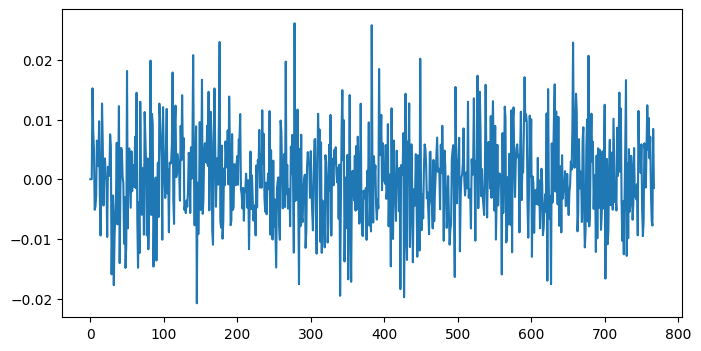

In [96]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(log_reg.coef_[0]);

In [97]:
for x, y in zip(val_x, val_y):
    print(np.linalg.norm(x - train_x[0]), np.linalg.norm(x-train_x[1]), y)

65.22247 65.43733 0
67.72304 69.42213 0
61.06353 60.74892 1
63.354164 63.382896 1
63.95588 65.914116 0
68.48421 69.28659 0
59.13788 62.937927 1
68.36181 69.131294 0
68.80104 68.429955 0
68.19193 68.54382 0
61.58481 48.567833 1
54.493763 58.37725 1
58.195633 65.01029 1
63.04625 61.86673 1
69.59611 68.24532 0
55.575466 63.046288 1
55.874138 50.09286 1
68.38377 69.13525 0
68.732544 69.34778 0
68.4479 68.12395 0
65.901596 68.12339 0
69.21488 68.71947 0
54.854446 42.459267 1
61.278717 60.486298 1
68.31735 69.23461 0
69.342064 69.28718 0
67.486755 68.18899 0
64.612564 66.95909 0
62.172848 49.243534 1
67.70617 69.84128 0
62.33406 63.717636 1
68.7677 69.70281 0
66.524826 65.327995 0
60.488934 65.06894 1
64.37007 64.51177 1
65.52529 64.199066 0
55.47905 60.345913 1
66.29765 68.31506 0
67.39787 68.25935 0
63.172726 62.508812 1
66.77 66.9672 0
64.957245 64.33355 0
55.937134 43.94248 1
48.76618 59.046513 1
59.572968 41.346134 1
60.182682 61.92605 1
69.438866 68.917274 0
60.486576 61.565674 1
68.71

# Inspecting CivilCommentsExtracted to see how well Y and S are predictable from encodings


**Bert**

512 examples
* Y acc = 87.4
* S acc = 96.5

full dataset (270k examples)
* Y acc@full = 89.9
* S acc@full = 97.7



In [20]:
ds = CivilCommentsExtracted(
    root_dir='/home/hrayrh/data',
    encoding_extractor='bert',
    # encoding_extractor='stroberta',
    # encoding_extractor='roberta',
    # encoding_extractor='roberta_large',
)

In [21]:
train = ds.get_subset('train')
val = ds.get_subset('val')
test = ds.get_subset('test')
print(f'{len(train)=}, {len(val)=}, {len(test)=}')

len(train)=269038, len(val)=45180, len(test)=133782


In [28]:
def compute_group_proportions(examples):
    g = 2 * examples[:, 2] + examples[:, 1]  # 2 * y + c
    return [np.mean(g==i) for i in range(4)]

In [29]:
train_X, examples = train[np.arange(len(train))]
print(f'{train_X.shape=}, {examples.shape=}')
train_s = examples[:, 1]
train_y = examples[:, 2]
print(f'{train_s.shape=}, {train_y.shape=}')
print(compute_group_proportions(examples))

train_X.shape=(269038, 768), examples.shape=(269038, 3)
train_s.shape=(269038,), train_y.shape=(269038,)
[0.8613578750957114, 0.025219485723206387, 0.10185921691359585, 0.011563422267486377]


In [30]:
val_X, examples = val[np.arange(len(val))]
print(f'{val_X.shape=}, {examples.shape=}')
val_s = examples[:, 1]
val_y = examples[:, 2]
print(f'{val_s.shape=}, {val_y.shape=}')
print(compute_group_proportions(examples))

val_X.shape=(45180, 768), examples.shape=(45180, 3)
val_s.shape=(45180,), val_y.shape=(45180,)
[0.8633466135458168, 0.024767596281540506, 0.10008853474988934, 0.01179725542275343]


In [31]:
test_X, examples = test[np.arange(len(test))]
print(f'{test_X.shape=}, {examples.shape=}')
test_s = examples[:, 1]
test_y = examples[:, 2]
print(f'{test_s.shape=}, {test_y.shape=}')
print(compute_group_proportions(examples))

test_X.shape=(133782, 768), examples.shape=(133782, 3)
test_s.shape=(133782,), test_y.shape=(133782,)
[0.8612743119403208, 0.02492861520981896, 0.10230823279663931, 0.011488840053220912]


In [27]:
examples[:20]

array([[ 0,  0,  1],
       [ 1,  0,  0],
       [ 2,  0,  0],
       [ 3,  0,  1],
       [ 4,  0,  0],
       [ 5,  0,  1],
       [ 6,  0,  1],
       [ 7,  0,  0],
       [ 8,  0,  1],
       [ 9,  1,  1],
       [10,  0,  1],
       [11,  0,  1],
       [12,  0,  0],
       [13,  0,  1],
       [14,  0,  0],
       [15,  0,  0],
       [16,  1,  1],
       [17,  0,  1],
       [18,  0,  1],
       [19,  0,  0]])

## Predicting Y

In [34]:
log_reg = LogisticRegression(max_iter=10000)
compute_group_proportions(examples)

# selected_indices = np.random.choice(np.arange(len(train_X)), 512, replace=False)
# log_reg.fit(train_X[selected_indices], train_y[selected_indices])

log_reg.fit(train_X, train_y)

val_pred = log_reg.predict(val_X)
val_acc = np.mean(val_pred == val_y)
print(f'predicting Y, {val_acc=}')

predicting Y, val_acc=0.899203187250996


## Predicting S

In [35]:
log_reg = LogisticRegression(max_iter=10000)

# selected_indices = np.random.choice(np.arange(len(train_X)), 512, replace=False)
# log_reg.fit(train_X[selected_indices], train_s[selected_indices])

log_reg.fit(train_X, train_s)

val_pred = log_reg.predict(val_X)
val_acc = np.mean(val_pred == val_s)
print(f'predicting S, {val_acc=}') 

predicting S, val_acc=0.9799247454625941


## Imbalanced contexts

In [40]:
def worst_group_acc(pred, y, s):
    g = 2 * y + s
    accs = []
    for g_idx in range(4):
        mask = (g == g_idx)
        g_acc = np.mean(pred[mask] == y[mask])
        accs.append(g_acc)
    print('group accuracies:', accs)
    print('overall accuracy:', np.mean(pred==y))
    return np.min(accs)

In [74]:
train_X, examples = train[np.arange(len(train))]
train_s = examples[:, 1]
train_y = examples[:, 2]
g = 2 * examples[:, 2] + examples[:, 1]  # 2 * y + c

target_group_proportions = [0.45, 0.05, 0.05, 0.45]
current_group_proportions = compute_group_proportions(examples)
current_group_counts = len(train) * np.array(current_group_proportions)
target_group_counts = len(train) * np.array(target_group_proportions)
c = np.min(current_group_counts / target_group_counts)
actual_group_counts = c * target_group_counts / 7  # this results in about 1000 total examples, same as for 512 context_class_size

In [75]:
print(current_group_counts)
print(target_group_counts)
print(actual_group_counts)

[231738.   6785.  27404.   3111.]
[121067.1  13451.9  13451.9 121067.1]
[444.42857143  49.38095238  49.38095238 444.42857143]


In [76]:
train_mask = np.zeros(len(train), dtype=np.bool_)
g = 2 * examples[:, 2] + examples[:, 1]  # 2 * y + c

for i in range(4):
    g_indices = np.where(g == i)[0]
    selected_g_indices = np.random.choice(
        g_indices,
        int(actual_group_counts[i]),
        replace=False
    )
    train_mask[selected_g_indices] = True

print(np.sum(train_mask))
print(np.sum(actual_group_counts))

986
987.6190476190477


In [82]:
# normal ERM
log_reg = LogisticRegression(max_iter=1000)    
log_reg.fit(train_X[train_mask], train_y[train_mask])

# downsampled ERM
if False:
    log_reg = LogisticRegression(max_iter=1000)    
    X = train_X[train_mask]
    y = train_y[train_mask]
    s = train_s[train_mask]
    g = 2 * y + s
    counts = Counter(g)
    print(counts)
    min_count = np.min([counts[g_idx] for g_idx in counts])
    selected_indices = []
    for g_idx in range(4):
        selected_indices.append(
            np.random.choice(np.where(g==g_idx)[0], size=min_count, replace=False)
        )
    selected_indices=np.concatenate(selected_indices, axis=0)
    log_reg.fit(X[selected_indices], y[selected_indices])

In [83]:
val_pred = log_reg.predict(val_X)
print(f'predicting Y, matching Y, wg acc: {worst_group_acc(val_pred, val_y, val_s)}')

group accuracies: [0.8714556734861303, 0.28328865058087577, 0.40026536930561696, 0.8836772983114447]
overall accuracy: 0.8098716246126605
predicting Y, matching Y, wg acc: 0.28328865058087577


In [84]:
val_pred = log_reg.predict(val_X)
print(f'predicting Y, matching S, wg acc: {worst_group_acc(val_pred, val_s, val_y)}')

group accuracies: [0.8714556734861303, 0.599734630694383, 0.7167113494191242, 0.8836772983114447]
overall accuracy: 0.8405710491367862
predicting Y, matching S, wg acc: 0.599734630694383
